# Venture Investment Market Analysis: Startups


- Author: Nila Sisakyan
- Date: June 1, 2026

## Introduction

### Project Goals and Objectives

**Goal:** Conduct exploratory analysis of historical startup funding data to help a venture capital firm select an optimal investment strategy — an industry and funding type.

**Objectives:**
1. Load the data, assess its quality, and prepare it for analysis.
2. Group companies by funding duration and classify market segments as mainstream, mid-sized, or niche.
3. Identify typical funding amounts, exclude anomalies, and compare funding types by popularity and volume.
4. Analyze investment trends by year and assess the stability of returns by funding type.
5. Formulate final conclusions and recommendations for the investor.

### Data Description

Two datasets are used for the analysis:

- `cb_investments.csv` — information on companies and funding raised
- `cb_returns.csv` — return amounts by year and funding type

#### `cb_investments.csv` Dataset Description

- `name` — company name;
- `homepage_url` — link to the company website;
- `category_list` — categories in which the company operates, separated by |;
- `market` — the company's primary market or industry;
- `funding_total_usd` — total investment raised in US dollars;
- `status` — current company status, such as operating, closed, etc.;
- `country_code` — country code, such as USA;
- `state_code` — state or regional code, such as CA;
- `region` — region, such as SF Bay Area;
- `city` — city where the company is located;
- `funding_rounds` — total number of funding rounds;
- `participants` — number of participants in funding rounds;
- `founded_at` — company founding date;
- `founded_month` — founding month in YYYY-MM format;
- `founded_quarter` — founding quarter in YYYY-QN format;
- `founded_year` — founding year;
- `first_funding_at` — first funding date;
- `mid_funding_at` — date of the funding round in the middle of the timeline;
- `last_funding_at` — last funding date;
- `seed` — seed investment amount;
- `venture` — venture capital investment amount;
- `equity_crowdfunding` — amount raised through equity crowdfunding;
- `undisclosed` — funding amount of an undisclosed type;
- `convertible_note` — investment amount through convertible notes;
- `debt_financing` — debt financing amount;
- `angel` — investment amount from angel investors;
- `grant` — grants received;
- `private_equity` — private equity investment amount;
- `post_ipo_equity` — post-IPO financing amount;
- `post_ipo_debt` — post-IPO debt financing amount;
- `secondary_market` — secondary market transaction amount;
- `product_crowdfunding` — amount raised through product crowdfunding;
- `round_A` — `round_H` — investment amount in the corresponding round.

#### `cb_returns.csv` Dataset Description

- `year` — year of returns;
- `seed` — returns from seed investments;
- `venture` — returns from venture capital investments;
- `equity_crowdfunding` — returns from equity crowdfunding;
- `undisclosed` — returns of an undisclosed type;
- `convertible_note` — returns through convertible notes;
- `debt_financing` — returns from debt financing;
- `angel` — returns to angel investors;
- `grant` — returns from grants;
- `private_equity` — returns from private equity investments;
- `post_ipo_equity` — returns from IPOs;
- `post_ipo_debt` — returns from debt IPOs;
- `secondary_market` — returns from secondary market transactions;
- `product_crowdfunding` — returns from product crowdfunding.

### Project Contents

1. Data loading and preprocessing.
2. Feature engineering.
3. Outlier handling and funding type analysis.
4. Trend analysis.
5. Final conclusions and recommendations.

## Data Loading and Preprocessing

We will start by loading the libraries and the `cb_investments` and `cb_returns` datasets. We will use `pandas`, the data visualization libraries `matplotlib` and `seaborn`, and `phik` to build a correlation matrix. The datasets will be stored in two variables: `investments_df` and `returns_df`.

In [1]:
# Import libraries
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix

In [2]:
# Load datasets into variables
investments_df = pd.read_csv(
    'https://code.s3.yandex.net/datasets/cb_investments.zip',
    sep=';',
    low_memory=False
)

returns_df = pd.read_csv(
    'https://code.s3.yandex.net/datasets/cb_returns.csv')

Explore the `cb_investments` dataset by displaying its first rows with `head()` and DataFrame information with `info()`:

In [3]:
# Display the first rows of the DataFrame
investments_df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# Display DataFrame information
investments_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  str    
 1   homepage_url          45989 non-null  str    
 2   category_list         45477 non-null  str    
 3    market               45477 non-null  str    
 4    funding_total_usd    49438 non-null  str    
 5   status                48124 non-null  str    
 6   country_code          44165 non-null  str    
 7   state_code            30161 non-null  str    
 8   region                44165 non-null  str    
 9   city                  43322 non-null  str    
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  str    
 13  founded_month         38482 non-null  str    
 14  founded_quarter       38482 non-null  str    
 15  founded_year          38554 no

In [5]:
# Store the original row count
initial_rows = investments_df.shape[0]

Now explore the `returns_df` dataset:

In [6]:
returns_df.head(15)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
5,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
7,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
8,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02


In [7]:
# Display DataFrame information
returns_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


### Preliminary Findings from the Initial Data Exploration

The `cb_investments` dataset contains 54,294 rows and 40 columns with information on companies and their funding.

The initial analysis identifies the following characteristics:

- Two column names have an extra space: ` market` and ` funding_total_usd` — they need to be renamed.
- `funding_total_usd` is stored as `object`, probably due to thousands separators (e.g., `1,000,000`) — it needs to be converted to a numeric type.
- The date columns (`founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at`) have the `object` type — they need to be converted to `datetime`.
- `mid_funding_at` has substantial missing values — 19,150 out of 49,438. According to the assignment, these should be filled using `first_funding_at` and `last_funding_at`.
- `funding_rounds` and `participants` store small integers as `float64` — they can be optimized to `Int8`. `founded_year` can also be converted to `Int16`.
- Rows without funding data (54,294 − 49,438 = 4,856 rows) should be removed.


The `cb_returns` dataset contains 15 rows and 14 columns — one row per year.

The initial analysis identifies the following characteristics:
   - There are no explicit missing values. Zero values occur for some funding types, but appear to reflect actual historical market trends rather than missing data.
   - Financial metrics are floating-point numbers with fractional values, so converting them to integer types is not appropriate.
   - The `year` column should be set as the index.

### Data Preprocessing

#### Changing DataFrame Column Names or Labels

In [8]:
# Remove extra spaces from column names
investments_df.columns = investments_df.columns.str.strip()

In [9]:
# Set year as the index for returns_df
returns_df = returns_df.set_index('year')

#### Optimizing Data Types

In [10]:
# Replace the separator with a space for funding_total_usd
investments_df['funding_total_usd'] = (investments_df['funding_total_usd'].astype(str).str.replace(',', '', regex=False))

# Convert funding_total_usd to a numeric type
investments_df['funding_total_usd'] = pd.to_numeric(
    investments_df['funding_total_usd'], errors='coerce'
).astype('Int64')

In [11]:
# Convert date columns to datetime
date_cols = [
    'founded_at',
    'first_funding_at',
    'mid_funding_at',
    'last_funding_at'
]

for col in date_cols:
    investments_df[col] = pd.to_datetime(investments_df[col], errors='coerce')

In [12]:
# Optimize data types
investments_df['funding_rounds'] = investments_df['funding_rounds'].astype('Int8')
investments_df['participants'] = investments_df['participants'].astype('Int8')
investments_df['founded_year'] = investments_df['founded_year'].astype('Int16')

#### Handling Missing Values in investments_df

In [13]:
# Fill mid_funding_at with the approximate midpoint between first_funding_at and last_funding_at
mask = investments_df['mid_funding_at'].isna()

investments_df.loc[mask, 'mid_funding_at'] = (
    investments_df.loc[mask, 'first_funding_at']
    + (investments_df.loc[mask, 'last_funding_at'] - investments_df.loc[mask, 'first_funding_at']) / 2
)

In [14]:
# Remove rows with missing funding_total_usd values
investments_df = investments_df.dropna(subset=['funding_total_usd'])

Determine the absolute number and relative share of missing values in investments_df:

In [15]:
# Find the absolute count
investments_df.isna().sum()

name                        1
homepage_url             2314
category_list            2503
market                   2503
funding_total_usd           0
status                   1105
country_code             3819
state_code              15288
region                   3819
city                     4505
funding_rounds              0
participants            13576
founded_at               8706
founded_month            8772
founded_quarter          8772
founded_year             8706
first_funding_at            0
mid_funding_at              0
last_funding_at             0
seed                        0
venture                     0
equity_crowdfunding         0
undisclosed                 0
convertible_note            0
debt_financing              0
angel                       0
grant                       0
private_equity              0
post_ipo_equity             0
post_ipo_debt               0
secondary_market            0
product_crowdfunding        0
round_A                     0
round_B   

In [16]:
# Calculate the share of rows with missing values
investments_df.isna().sum() / investments_df.shape[0]

name                    0.000024
homepage_url            0.056567
category_list           0.061188
market                  0.061188
funding_total_usd       0.000000
status                  0.027012
country_code            0.093358
state_code              0.373726
region                  0.093358
city                    0.110128
funding_rounds          0.000000
participants            0.331875
founded_at              0.212824
founded_month           0.214438
founded_quarter         0.214438
founded_year            0.212824
first_funding_at        0.000000
mid_funding_at          0.000000
last_funding_at         0.000000
seed                    0.000000
venture                 0.000000
equity_crowdfunding     0.000000
undisclosed             0.000000
convertible_note        0.000000
debt_financing          0.000000
angel                   0.000000
grant                   0.000000
private_equity          0.000000
post_ipo_equity         0.000000
post_ipo_debt           0.000000
secondary_

In [17]:
# Remove missing first_funding_at values
investments_df = investments_df.dropna(subset=['first_funding_at'])

In [18]:
# Fill missing market values
investments_df['market'] = investments_df['market'].fillna('unknown')

In [19]:
# Fill missing founded_year values
investments_df['founded_year'] = pd.to_datetime(investments_df['founded_at']).dt.year

In [20]:
# Find and display the number of removed rows
deleted_rows = initial_rows - investments_df.shape[0]
deleted_rows

13387

In [21]:
# Find and display the percentage of removed rows
deleted_percent = deleted_rows / initial_rows * 100
deleted_percent

24.656499797399345

During missing value handling, key features needed for further analysis of startup investment activity were cleaned and reconstructed.

   - Missing values in `mid_funding_at` were reconstructed using available information on the first and last funding rounds.
   - Rows with missing `funding_total_usd` values were removed.
   - Missing values in `market` were filled with `unknown`.
   - A total of 13,389 rows were removed, approximately 24.7% of the original dataset.

#### Exact and Implicit Duplicates in the Data

In [22]:
# Check for fully duplicated rows
investments_df.duplicated().sum()

np.int64(0)

In [23]:
# Remove extra spaces in text data
for col in ['market', 'status', 'country_code', 'state_code']:
    investments_df[col] = investments_df[col].str.strip()

In [24]:
# Display the number of unique values by column
for col in ['market', 'status', 'country_code', 'state_code']:
    print(f'\n{col}')
    print('Unique values:', investments_df[col].unique())


market
Unique values: <StringArray>
[            'Education',               'unknown',     'Business Services',
          'Social Media',   'Hardware + Software',         'Biotechnology',
           'Hospitality',   'Enterprise Software',         'Manufacturing',
               'Finance',
 ...
 'Assisitive Technology',         'IT Management',      'Natural Gas Uses',
       'Clinical Trials',            'Employment', 'Real Estate Investors',
 'Business Productivity',   'Mining Technologies',             'Musicians',
                  'Gold']
Length: 395, dtype: str

status
Unique values: <StringArray>
['operating', 'acquired', nan, 'closed']
Length: 4, dtype: str

country_code
Unique values: <StringArray>
['USA',   nan, 'DEU', 'IND', 'CHE', 'PHL', 'ISR', 'ITA', 'JPN', 'GBR',
 ...
 'MMR', 'BHR', 'GTM', 'OMN', 'TTO', 'MKD', 'KWT', 'LIE', 'ZWE', 'CIV']
Length: 111, dtype: str

state_code
Unique values: <StringArray>
['MA',  nan, 'DE', 'MI', 'OH', 'LA', 'NC', 'VA', 'CA', 'FL', 'MD', 'NJ'

During preprocessing, categorical feature quality was checked, including missing values, exact and implicit duplicates, and text formatting.
The dataset contains no fully duplicated rows, confirming the absence of repeated observations across all features.
   - `market` — values use a consistent format (Title Case); no differences caused by capitalization or technical entry errors were identified. However, the data contains semantically related but formally distinct categories (e.g., Finance, Financial Services, Finance Technology, Personal Finance; Games, Game, Video Games, Mobile Games; Health Care, Medical, Healthcare Services). These differences reflect the actual industry structure rather than entry errors, so the values were not merged to avoid distorting the domain.
   - `status` — values use a consistent format (operating, acquired, closed). No implicit duplicates were identified.
   - Geographic features (`country_code`, `state_code`) — data is standardized (ISO country and regional codes). No capitalization or formatting issues were found.

### Preprocessing Summary

The data has been made consistent and correctly formatted: missing values were handled, data types converted, categorical features checked and normalized, and the absence of exact duplicates confirmed.

Categorical fields use consistent formatting, and no critical errors or inconsistencies were identified. After cleaning, the dataset was retained with minimal loss of observations.

The data is ready for feature engineering and further exploratory analysis.

## Feature Engineering

At this stage, new features are constructed to analyze the structure of startup investment activity. The goal is to identify key company characteristics affecting funding volume and trends, and to simplify further market analysis by grouping observations according to meaningful features.

### Groups by Funding Duration

In [25]:
# Calculate duration in days
investments_df['funding_duration_days'] = (
    investments_df['last_funding_at'] - investments_df['first_funding_at']
).dt.days

In [26]:
# Divide companies into groups
def funding_group(row):
    if row['funding_rounds'] == 1:
        return 'One-off funding'
    elif row['funding_duration_days'] <= 365:
        return 'Funding duration up to one year'
    else:
        return 'Funding duration over one year'

investments_df['funding_group'] = investments_df.apply(funding_group, axis=1)

In [27]:
# Express groups as percentages of company count
group_counts = investments_df['funding_group'].value_counts(normalize=True) * 100
group_counts

funding_group
One-off funding                    58.945902
Funding duration over one year     30.051092
Funding duration up to one year    11.003007
Name: proportion, dtype: float64

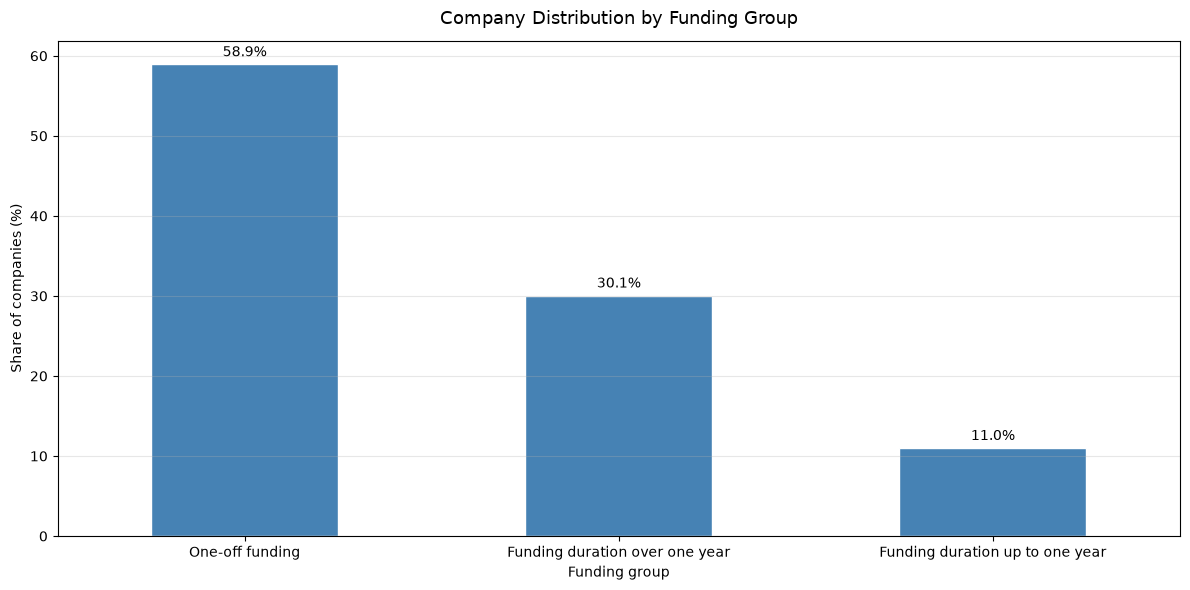

In [28]:
# Create a chart
fig, ax = plt.subplots(figsize=(12, 6))

group_counts.plot(
    kind='bar',
    ax=ax,
    color='steelblue',
    edgecolor='white'
)

# value labels
for i, v in enumerate(group_counts.values):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=10)

ax.set_title('Company Distribution by Funding Group', fontsize=13, pad=12)
ax.set_xlabel('Funding group')
ax.set_ylabel('Share of companies (%)')

ax.grid(axis='y', alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [29]:
# Calculate total investments by group
group_money = investments_df.groupby('funding_group')['funding_total_usd'].sum().sort_values(ascending=False)
group_money

funding_group
Funding duration over one year     402743297604
One-off funding                    199304424483
Funding duration up to one year     48885981057
Name: funding_total_usd, dtype: Int64

In [30]:
# Express groups as percentages of investment volume
group_money_share = group_money / group_money.sum() * 100
group_money_share

funding_group
Funding duration over one year     61.871631
One-off funding                    30.618237
Funding duration up to one year     7.510132
Name: funding_total_usd, dtype: Float64

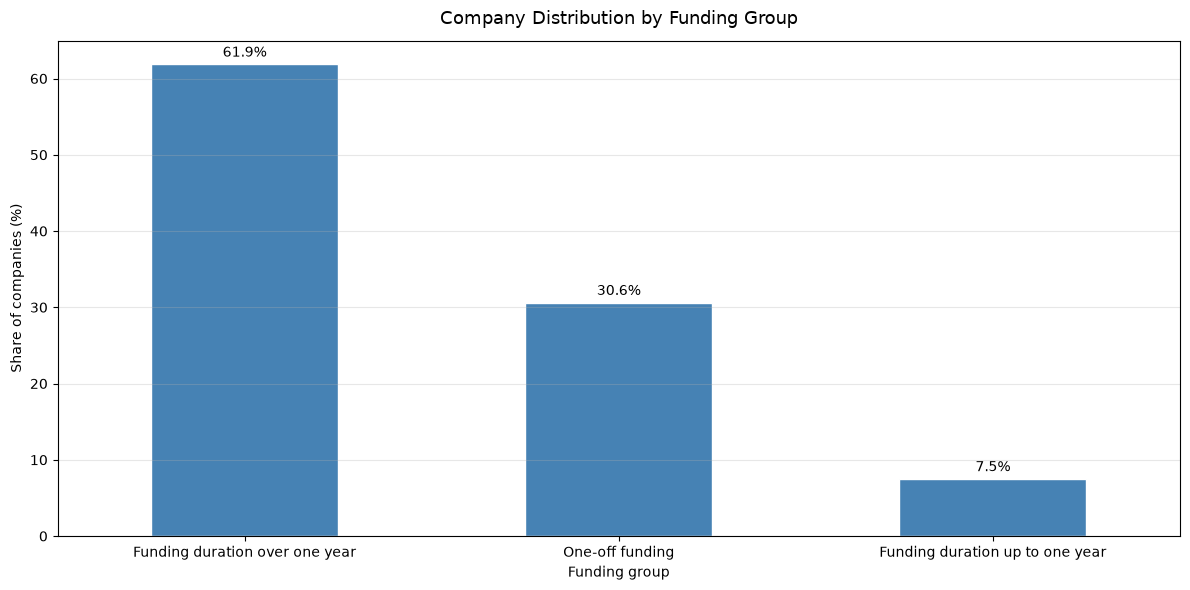

In [31]:
# Create a chart
fig, ax = plt.subplots(figsize=(12, 6))

group_money_share.plot(
    kind='bar',
    ax=ax,
    color='steelblue',
    edgecolor='white'
)

# value labels
for i, v in enumerate(group_money_share.values):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=10)

ax.set_title('Company Distribution by Funding Group', fontsize=13, pad=12)
ax.set_xlabel('Funding group')
ax.set_ylabel('Share of companies (%)')

ax.grid(axis='y', alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The analysis of company distributions by investment activity duration shows a pronounced imbalance between the number of companies and the amount of capital raised.
   - Most companies receive funding in only one round, indicating a high share of short-term investment deals.
   - Despite representing a smaller share of companies, projects with longer funding periods accumulate most of the capital.

<b>Summary:</b>
The structure is characteristic of the venture capital market: short-term investments dominate by company count, while most financial resources are concentrated in projects with long investment cycles.

### Identifying Mid-sized and Niche Market Segments

In [32]:
# Calculate segment frequencies
market_counts = investments_df['market'].value_counts()
market_counts

market
Software                 4812
Biotechnology            3590
unknown                  2503
Mobile                   2344
E-Commerce               1866
                         ... 
Employment                  1
Real Estate Investors       1
Business Productivity       1
Musicians                   1
Gold                        1
Name: count, Length: 395, dtype: int64

In [33]:
# Classify segments
def classify_market(count):
    if count > 120:
        return 'mass'
    elif 35 <= count <= 120:
        return 'mid'
    else:
        return 'niche'

market_type = market_counts.apply(classify_market)
market_type

market
Software                  mass
Biotechnology             mass
unknown                   mass
Mobile                    mass
E-Commerce                mass
                         ...  
Employment               niche
Real Estate Investors    niche
Business Productivity    niche
Musicians                niche
Gold                     niche
Name: count, Length: 395, dtype: str

In [34]:
# Count segments in each group
segment_distribution = market_type.value_counts()
segment_distribution

count
niche    289
mid       57
mass      49
Name: count, dtype: int64

In [35]:
# Sort segments by company count in descending order
market_counts_sorted = market_counts.sort_values(ascending=False).reset_index()
market_counts_sorted.columns = ['market', 'count']
market_counts_sorted.head()

,market,count
0,Software,4812
1,Biotechnology,3590
2,unknown,2503
3,Mobile,2344
4,E-Commerce,1866


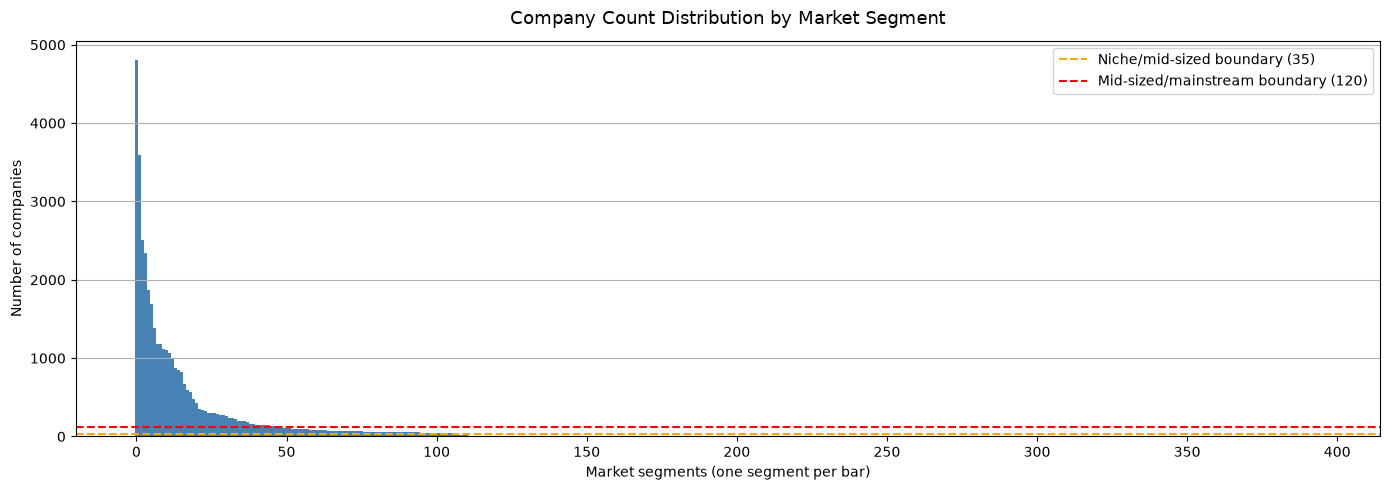

In [36]:
# Create a chart
fig, ax = plt.subplots(figsize=(14, 5))

# Use the index on the X-axis for evenly spaced bars
ax.bar(
    range(len(market_counts_sorted)),
    market_counts_sorted['count'],      
    color='steelblue',
    width=1.0,                        
    edgecolor='none'
)

# Add vertical boundary lines between groups
ax.axhline(35, color='orange', linestyle='--', linewidth=1.5, 
           label='Niche/mid-sized boundary (35)')
ax.axhline(120, color='red', linestyle='--', linewidth=1.5, 
           label='Mid-sized/mainstream boundary (120)')

ax.set_title('Company Count Distribution by Market Segment', 
             fontsize=13, pad=12)
ax.set_xlabel('Market segments (one segment per bar)')
ax.set_ylabel('Number of companies')
ax.legend()
ax.grid(axis='y')

plt.tight_layout()
plt.show()

For readability, add colors for each segment according to its group and limit the Y-axis:

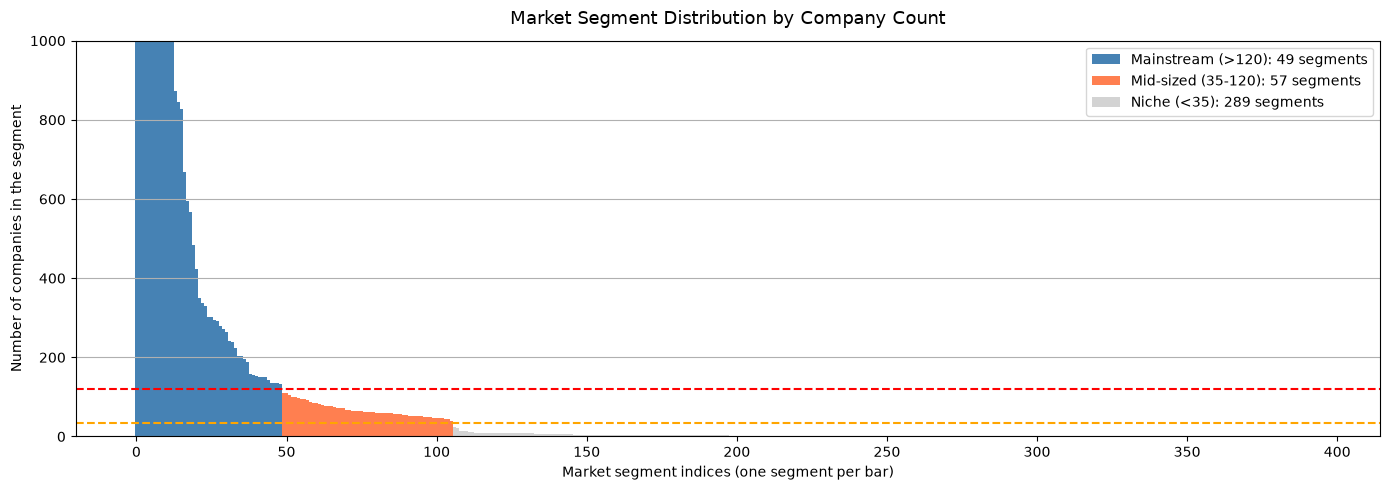

In [37]:
# Assign a color to each segment based on its group
colors = market_counts_sorted['count'].apply(
    lambda x: 'steelblue' if x > 120 else ('coral' if x >= 35 else 'lightgray')
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(
    range(len(market_counts_sorted)),
    market_counts_sorted['count'],
    color=colors,
    width=1.0,
    edgecolor='none'
)

# Limit the Y-axis for more readable boundaries
ax.set_ylim(0, 1000)

# Boundaries between groups
ax.axhline(35, color='orange', linestyle='--', linewidth=1.5,
           label='Niche/mid-sized boundary (35)')
ax.axhline(120, color='red', linestyle='--', linewidth=1.5,
           label='Mid-sized/mainstream boundary (120)')

# Legend for group colors
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='steelblue', label='Mainstream (>120): 49 segments'),
    Patch(facecolor='coral', label='Mid-sized (35-120): 57 segments'),
    Patch(facecolor='lightgray', label='Niche (<35): 289 segments')
]
ax.legend(handles=legend_elements)

ax.set_title('Market Segment Distribution by Company Count',
             fontsize=13, pad=12)
ax.set_xlabel('Market segment indices (one segment per bar)')
ax.set_ylabel('Number of companies in the segment')
ax.grid(axis='y')

plt.tight_layout()
plt.show()

Retain only mainstream segments in the market column. Replace the other segment values with placeholders — niche for niche segments and mid for mid-sized segments:

In [38]:
# Create a mapping dictionary: segment name -> segment type
market_type_dict = market_type.to_dict()

investments_df['market'] = investments_df['market'].apply(
    lambda x: x if market_type_dict.get(x) == 'mass' 
    else ('mid' if market_type_dict.get(x) == 'mid' 
    else 'niche')
)

# Check the result
investments_df['market'].value_counts().head()

market
Software         4812
mid              3841
Biotechnology    3590
unknown          2503
Mobile           2344
Name: count, dtype: int64

The dataset contains **395 unique market segments**. After classification by frequency, they are distributed as follows:

- **Mainstream** (more than 120 companies): 49 segments
- **Mid-sized** (35 to 120 companies): 57 segments
- **Niche** (fewer than 35 companies): 289 segments

The vast majority of segments are niche (73%), reflecting the highly fragmented startup market. Mainstream segments are few, but concentrate most companies. Individual niche and mid-sized segments were replaced with the `niche` and `mid` placeholders to simplify further analysis.

### Feature Engineering Summary

Two new features were created to structure further market analysis.

**Groups by funding duration:**
Most companies receive funding in a single round — these are short-term investment deals. However, most capital is concentrated in companies with long investment cycles (over a year), which raise the largest amounts. This is characteristic of the venture capital market: few companies go through a long funding journey, but they receive the lion's share of investments.

**Market segments:**
The startup market is highly fragmented — 289 of 395 segments are niche. There are only 49 mainstream segments, but they concentrate the largest number of companies. To simplify the analysis, niche and mid-sized segments were combined into the `niche` and `mid` groups, respectively.

The new features are ready for the next stage — outlier handling and funding type analysis.

## Outlier Handling and Funding Type Analysis

### Analyzing and Flagging Outliers in Each Segment

Examine the statistical metrics of the `funding_total_usd` column

In [39]:
investments_df['funding_total_usd'].describe()

count             40907.0
mean      15912526.050407
std      168678800.166966
min                   1.0
25%              350000.0
50%             2000000.0
75%            10000000.0
max         30079503000.0
Name: funding_total_usd, dtype: Float64

Create a histogram and boxplot for `funding_total_usd`

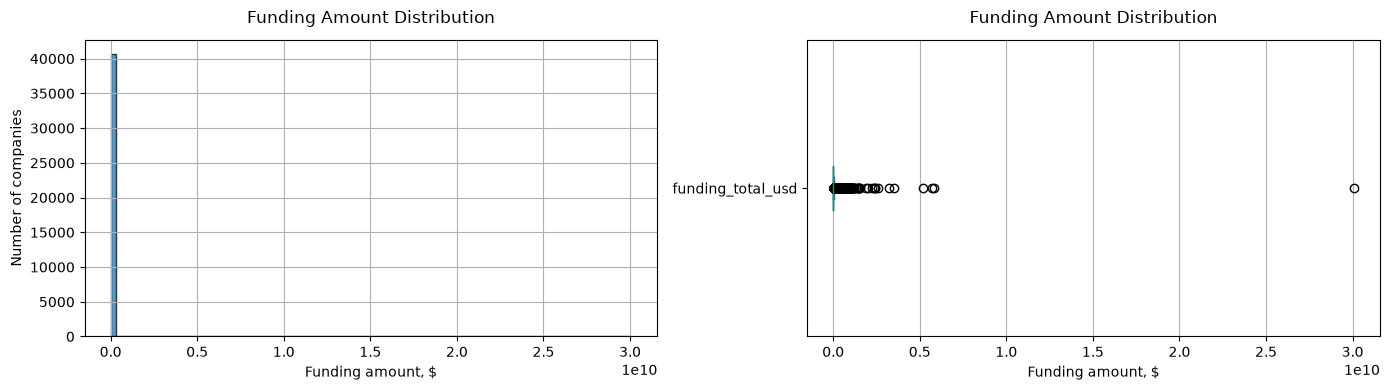

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

investments_df['funding_total_usd'].dropna().plot(
    kind='hist',
    bins=100,
    ax=axes[0],
    edgecolor='black',
    alpha=0.75
)

axes[0].set_title('Funding Amount Distribution', fontsize=12, pad=12)
axes[0].set_xlabel('Funding amount, $')
axes[0].set_ylabel('Number of companies')
axes[0].grid()

investments_df['funding_total_usd'].dropna().plot(
    kind='box',
    vert=False,
    ax=axes[1]
)

axes[1].set_title('Funding Amount Distribution', fontsize=12, pad=12)
axes[1].set_xlabel('Funding amount, $')
axes[1].grid(axis='x')

plt.tight_layout()
plt.show()

Create a boxplot with outliers hidden to make typical values easier to see:

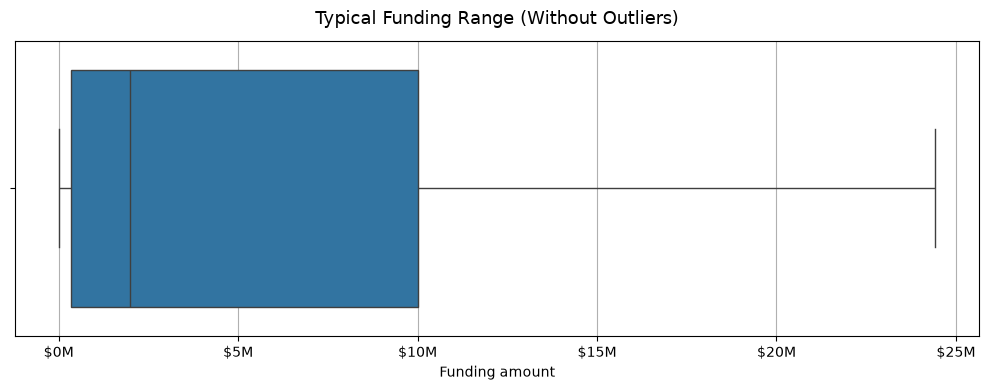

In [41]:
# Create a boxplot with outliers hidden
fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(
    data=investments_df,
    x='funding_total_usd',
    ax=ax,
    showfliers=False
)

# Format the X-axis in millions of dollars for readability
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'${x/1e6:.0f}M')
)

ax.set_title('Typical Funding Range (Without Outliers)',
             fontsize=13, pad=12)
ax.set_xlabel('Funding amount')
ax.grid(axis='x')

plt.tight_layout()
plt.show()

Calculate the exact values:

In [42]:
q1 = investments_df['funding_total_usd'].quantile(0.25)
median = investments_df['funding_total_usd'].median()
q3 = investments_df['funding_total_usd'].quantile(0.75)
iqr = q3 - q1

# Boxplot whisker boundaries (1.5 * IQR)
lower_whisker = q1 - 1.5 * iqr
upper_whisker = q3 + 1.5 * iqr

print(f'Q1: ${q1:,.0f}')
print(f'Median: ${median:,.0f}')
print(f'Q3: ${q3:,.0f}')
print(f'Upper whisker: ${upper_whisker:,.0f}')

Q1: $350,000
Median: $2,000,000
Q3: $10,000,000
Upper whisker: $24,475,000


Apply the IQR method separately to each segment and calculate the total number and share of outliers:

In [43]:
# Calculate IQR for the segment
def get_outliers_iqr(group):
    q1 = group['funding_total_usd'].quantile(0.25)
    q3 = group['funding_total_usd'].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return group[(group['funding_total_usd'] < lower) | 
                 (group['funding_total_usd'] > upper)].index

outlier_indices = investments_df.groupby('market').apply(get_outliers_iqr).explode()

# Flag outliers in the DataFrame
investments_df['is_outlier'] = investments_df.index.isin(outlier_indices)

print('Number of outliers:', investments_df['is_outlier'].sum())
print(f'Outlier share: {investments_df["is_outlier"].mean():.1%}')

Number of outliers: 5244
Outlier share: 12.8%


Display the top 10 segments with the highest outlier shares (excluding niche and mid):

In [44]:
# Calculate the outlier share for each segment
outlier_share = (investments_df.groupby('market')['is_outlier']
                 .agg(['sum', 'count'])
                 .assign(share=lambda x: x['sum'] / x['count'] * 100)
                 .sort_values('share', ascending=False))

# Display the top 10 mainstream segments with the highest outlier shares
top_outliers = outlier_share[~outlier_share.index.isin(['niche', 'mid'])].head(10)
top_outliers

,sum,count,share
market,,,
Real Estate,48,279,17.204301
Entertainment,25,150,16.666667
Consulting,58,349,16.618911
Search,48,291,16.494845
Cloud Computing,25,152,16.447368
Photography,33,204,16.176471
SaaS,44,272,16.176471
Technology,38,238,15.966387
Video,30,188,15.957447


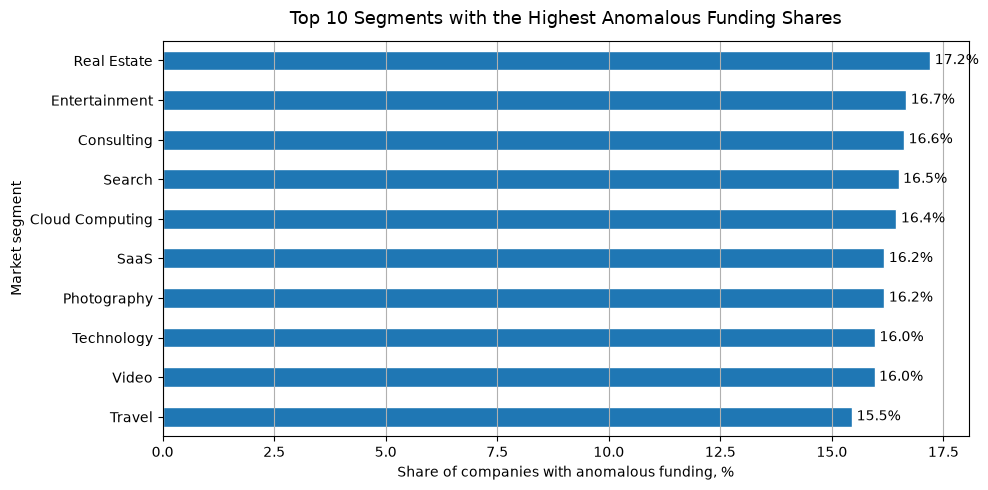

In [45]:
# Create a chart
fig, ax = plt.subplots(figsize=(10, 5))

top_outliers['share'].sort_values().plot(
    kind='barh',
    ax=ax,
    edgecolor='white'
)

for i, v in enumerate(top_outliers['share'].sort_values()):
    ax.text(v + 0.1, i, f'{v:.1f}%', va='center', fontsize=10)

ax.set_title('Top 10 Segments with the Highest Anomalous Funding Shares',
             fontsize=13, pad=12)
ax.set_xlabel('Share of companies with anomalous funding, %')
ax.set_ylabel('Market segment')
ax.grid(axis='x')

plt.tight_layout()
plt.show()

The boxplot without outliers shows that the **typical funding amount** for a company ranges from **0 to 12.1M** (whisker boundaries). The interquartile range is **250K to 5M**, and the median is **1.31M**.

Anything above $12.1M represents anomalous funding and will be excluded from further analysis using the IQR method for each segment.

The IQR method identified 5,235 companies with anomalous funding (12.8% of all companies). Outlier boundaries were calculated separately for each segment to account for industry specifics.

The highest shares of anomalous funding occur in **Real Estate** (17.2%), **Entertainment** (16.7%), and **Consulting** (16.6%). The top 10 segments have fairly similar shares — 15.5% to 17.2% — indicating an even distribution of anomalies across the market overall.

### Defining the Analysis Period and Removing Anomalies

Start by checking the completeness of the data for 2014. Examine funding round counts by year:

In [46]:
# Extract the year from mid_funding_at and count rounds by year
rounds_by_year = (investments_df['mid_funding_at']
                  .dt.year
                  .value_counts()
                  .sort_index())

display(rounds_by_year)

mid_funding_at
1011       1
1921       1
1960       2
1979       1
1982       3
1983       1
1984       2
1985       3
1987       2
1989       1
1990       1
1992       4
1993       1
1994       4
1995       4
1996       4
1997       7
1998      13
1999      50
2000     103
2001      63
2002      70
2003      90
2004     150
2005     843
2006    1463
2007    2107
2008    2588
2009    3237
2010    4094
2011    4863
2012    6089
2013    8423
2014    6619
Name: count, dtype: int64

The data starts in 1921, but we are interested in the modern period. Examine the chart starting in 1999, when significant activity begins:

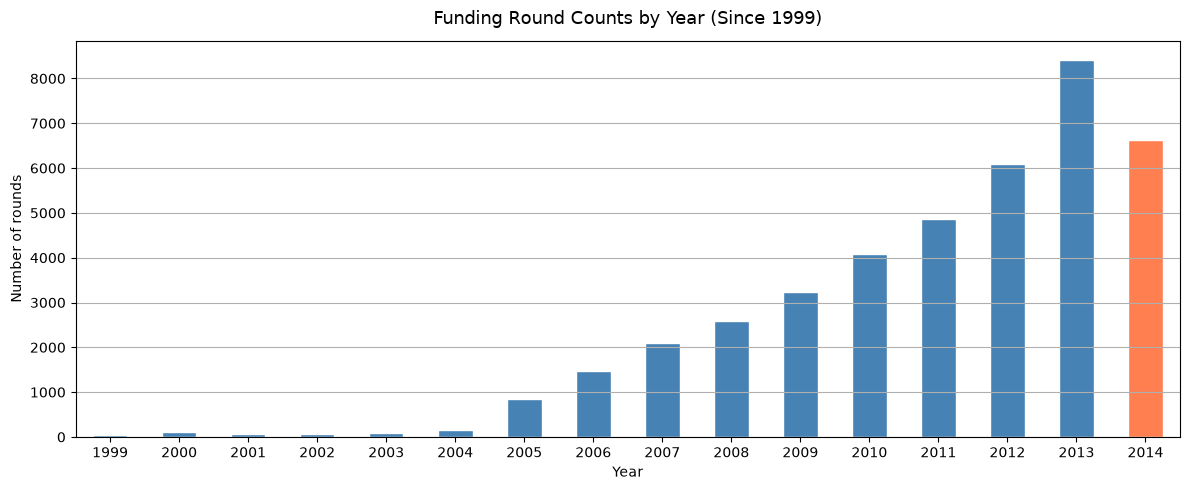

In [47]:
# Create a chart
rounds_by_year_filtered = rounds_by_year[rounds_by_year.index >= 1999]

fig, ax = plt.subplots(figsize=(12, 5))

rounds_by_year_filtered.plot(
    kind='bar',
    ax=ax,
    color='steelblue',
    edgecolor='white',
    rot=0
)

ax.patches[-1].set_facecolor('coral')

ax.set_title('Funding Round Counts by Year (Since 1999)', 
             fontsize=13, pad=12)
ax.set_xlabel('Year')
ax.set_ylabel('Number of rounds')
ax.grid(axis='y')

plt.tight_layout()
plt.show()

The chart confirms that the data for 2014 is **incomplete** — the number of rounds (6,619) fell sharply compared with 2013 (8,423), after steady growth throughout the preceding period. Most likely, the dataset was collected in mid-2014 and does not cover the full year.

In [48]:
# Remove companies with anomalous funding
investments_df = investments_df[investments_df['is_outlier'] == False]

print('Rows remaining after outlier removal:', len(investments_df))

Rows remaining after outlier removal: 35663


Filter for years with 50+ rounds:

In [49]:
# Count rounds by year using mid_funding_at
rounds_by_year_clean = (investments_df['mid_funding_at']
                        .dt.year
                        .value_counts()
                        .sort_index())
rounds_by_year_clean

mid_funding_at
1011       1
1921       1
1960       2
1979       1
1982       3
1983       1
1984       2
1985       3
1987       2
1989       1
1990       1
1992       4
1993       1
1994       4
1995       4
1996       3
1997       4
1998       9
1999      28
2000      65
2001      37
2002      48
2003      63
2004      96
2005     697
2006    1165
2007    1600
2008    1984
2009    2618
2010    3467
2011    4311
2012    5533
2013    7821
2014    6083
Name: count, dtype: int64

In [50]:
# Determine the first year with 50+ rounds
first_valid_year = rounds_by_year_clean[rounds_by_year_clean >= 50].index.min()
print('First year with 50+ rounds:', first_valid_year)

# Retain all companies from this year onward
investments_df = investments_df[
    investments_df['mid_funding_at'].dt.year >= first_valid_year
]

investments_df.shape

First year with 50+ rounds: 2000


(35588, 43)

The analysis of funding round counts by year shows that the data for **2014 is incomplete** — 6,083 rounds were recorded versus 7,821 in 2013, after steady growth throughout the preceding period. This means that the dataset was collected before the end of 2014.

After removing **5,235 companies with anomalous funding** (12.8%) and filtering from the first year with at least 50 funding rounds (2000), **35,587 companies** remained. The final sample covers 2000–2014 inclusive.

### Funding Type Analysis by Volume and Popularity

Calculate the total volume for each funding type:

In [51]:
# List of funding type columns
funding_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 
                 'convertible_note', 'debt_financing', 'angel', 'grant', 
                 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 
                 'secondary_market', 'product_crowdfunding']

# Calculate total volume for each funding type
funding_totals = investments_df[funding_types].sum().sort_values(ascending=False)
funding_totals

venture                 1.290922e+11
seed                    9.431332e+09
debt_financing          8.178153e+09
private_equity          4.843109e+09
angel                   2.481264e+09
undisclosed             2.100352e+09
grant                   1.978849e+09
post_ipo_equity         1.946452e+09
convertible_note        5.660394e+08
post_ipo_debt           2.867183e+08
equity_crowdfunding     2.379606e+08
product_crowdfunding    1.860939e+08
secondary_market        4.528580e+07
dtype: float64

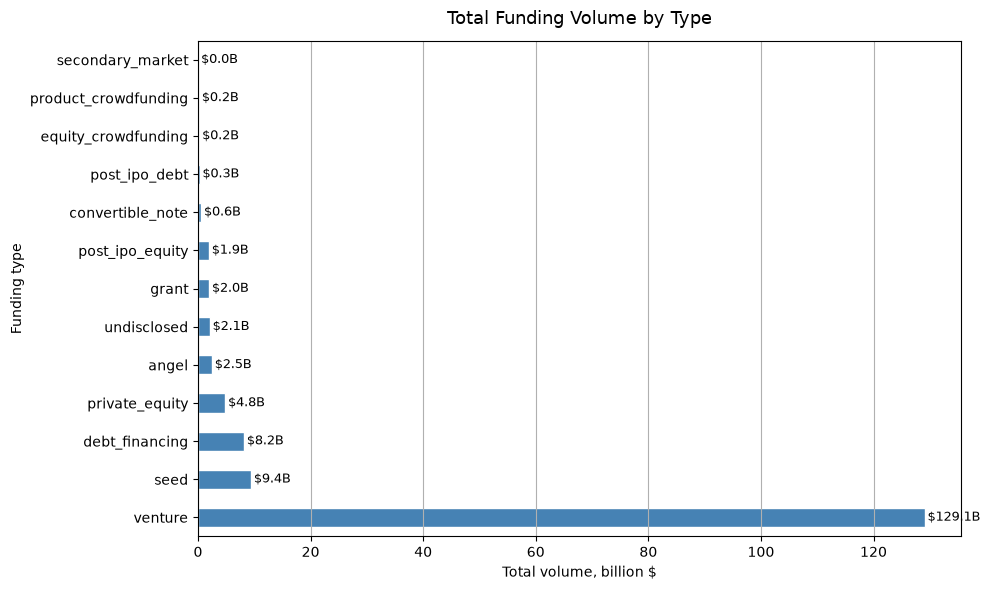

In [52]:
# Create a chart
fig, ax = plt.subplots(figsize=(10, 6))

# Convert to billions for readability
(funding_totals / 1e9).plot(
    kind='barh',
    ax=ax,
    color='steelblue',
    edgecolor='white'
)

# Add numerical values to each bar
for i, v in enumerate(funding_totals / 1e9):
    ax.text(v + 0.5, i, f'${v:.1f}B', va='center', fontsize=9)

ax.set_title('Total Funding Volume by Type', fontsize=13, pad=12)
ax.set_xlabel('Total volume, billion $')
ax.set_ylabel('Funding type')
ax.grid(axis='x')

plt.tight_layout()
plt.show()

Calculate popularity — how many companies used each funding type:

In [53]:
# Count companies with a nonzero value for each type
funding_popularity = (investments_df[funding_types] > 0).sum().sort_values(ascending=False)
funding_popularity

venture                 18820
seed                    13375
debt_financing           3265
angel                    2937
grant                    1003
undisclosed               813
private_equity            634
convertible_note          521
equity_crowdfunding       515
product_crowdfunding      204
post_ipo_equity           164
post_ipo_debt              27
secondary_market            7
dtype: int64

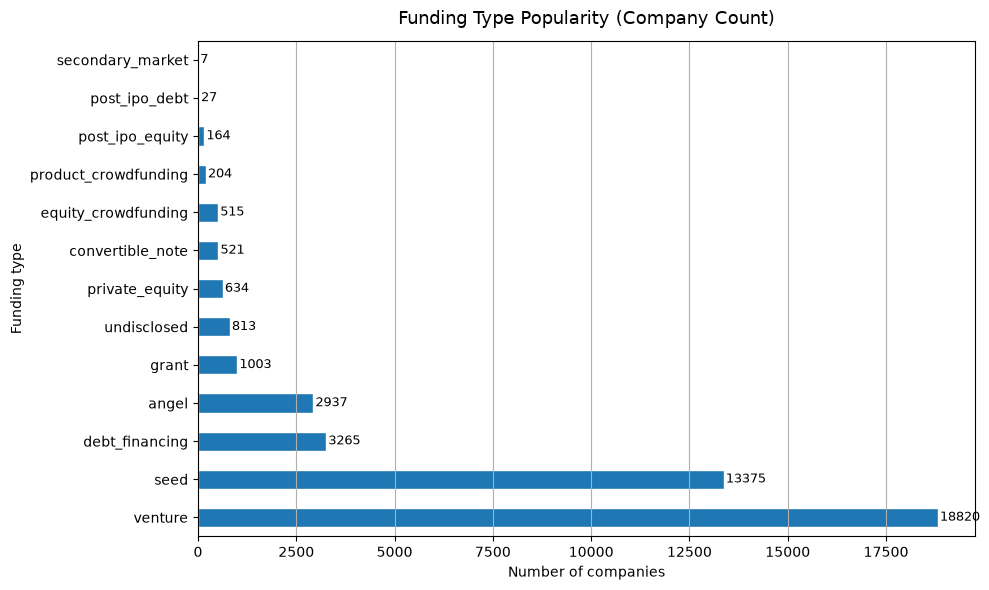

In [54]:
# Create a chart
fig, ax = plt.subplots(figsize=(10, 6))

funding_popularity.plot(
    kind='barh',
    ax=ax,
    edgecolor='white'
)

for i, v in enumerate(funding_popularity):
    ax.text(v + 50, i, str(v), va='center', fontsize=9)

ax.set_title('Funding Type Popularity (Company Count)',
             fontsize=13, pad=12)
ax.set_xlabel('Number of companies')
ax.set_ylabel('Funding type')
ax.grid(axis='x')

plt.tight_layout()
plt.show()

Plot total returns from different funding types over the full period:

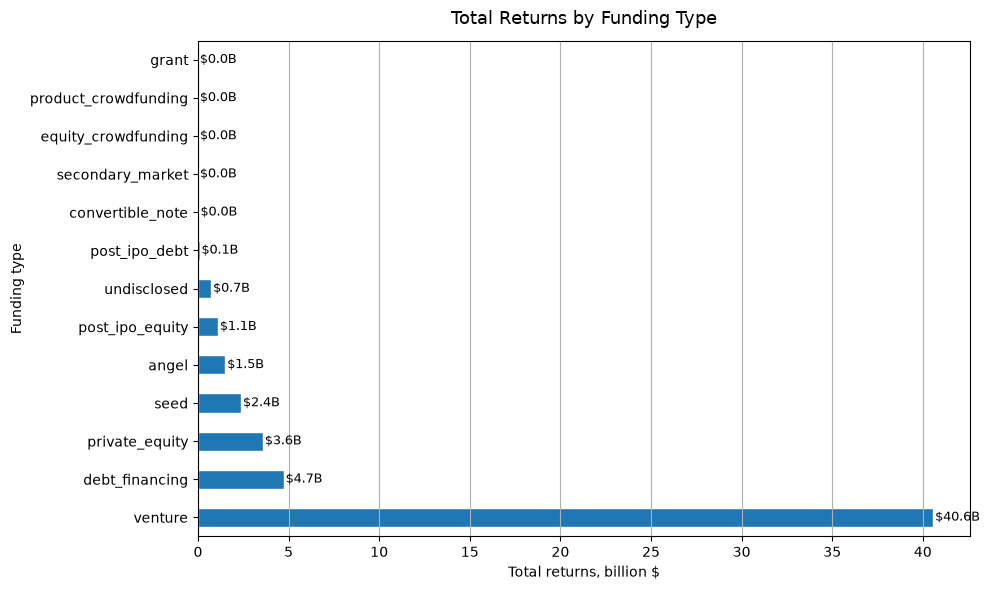

In [55]:
# Calculate total returns for each funding type
returns_totals = returns_df[funding_types].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))

# Convert to billions for readability
(returns_totals / 1e3).plot(
    kind='barh',
    ax=ax,
    edgecolor='white'
)

# Add numerical values to each bar
for i, v in enumerate(returns_totals / 1e3):
    ax.text(v + 0.1, i, f'${v:.1f}B', va='center', fontsize=9)

ax.set_title('Total Returns by Funding Type',
             fontsize=13, pad=12)
ax.set_xlabel('Total returns, billion $')
ax.set_ylabel('Funding type')
ax.grid(axis='x')

plt.tight_layout()
plt.show()

**Funding volume:**
The clear leader is **venture** (128.6B), several times larger than all other types. **Seed** (9.4B) ranks second, followed by **debt_financing** (8.2B) and **private_equity** (4.8B).

**Popularity:**
**Venture** (18,761) and **seed** (13,357) also lead by company count. **Debt_financing** (3,258) and **angel** (2,933) follow at a considerable distance.

**Comparing volume and popularity:**
- **Frequently used, but low volume:** `angel` — 2,933 companies, but only 2.5B; `grant` — 1,002 companies and 2.0B. These are widespread but relatively small investments.
- **Infrequent, but substantial volume:** `debt_financing` — 3,258 companies, but 8.2B; `private_equity` — only 632 companies, but 4.8B. These are large individual deals.

**Returns:**
Venture financing also leads in returns (40.6B), consistent with its dominant volume. Interestingly, **debt_financing** generates high returns (4.7B) with a relatively small number of companies, while **grant**, **equity_crowdfunding**, and **product_crowdfunding** generate almost no returns — consistent with their nature.

## Trend Analysis

### Annual Funding Trends

Calculate the average amount per funding round for each company:

In [56]:
# Calculate the average round amount for each company
investments_df['avg_round_usd'] = (investments_df['funding_total_usd'] / 
                                   investments_df['funding_rounds'])

investments_df['avg_round_usd'].describe()

count           35588.0
mean     2786691.830665
std      4974835.789669
min                 1.0
25%            200000.0
50%           1000000.0
75%           3200000.0
max          70000000.0
Name: avg_round_usd, dtype: Float64

Prepare the data for the charts:

In [57]:
# Extract the year from mid_funding_at
investments_df['mid_year'] = investments_df['mid_funding_at'].dt.year

# Calculate median round size by year
median_round_by_year = (investments_df.groupby('mid_year')['avg_round_usd']
                        .median())

# Calculate total rounds by year
total_rounds_by_year = (investments_df.groupby('mid_year')['funding_rounds']
                        .sum())

display(median_round_by_year)
display(total_rounds_by_year)

mid_year
2000         2250000.0
2001         1570886.0
2002         3225000.0
2003         1500000.0
2004         3000000.0
2005         4500000.0
2006         3900000.0
2007    2879166.666667
2008        2170743.75
2009         1498475.0
2010         1250000.0
2011          867685.0
2012          686000.0
2013          559000.0
2014          560625.0
Name: avg_round_usd, dtype: Float64

mid_year
2000      113
2001       66
2002       98
2003      125
2004      181
2005      948
2006     1849
2007     2842
2008     3663
2009     4617
2010     6136
2011     7578
2012     9707
2013    12880
2014     7122
Name: funding_rounds, dtype: Int64

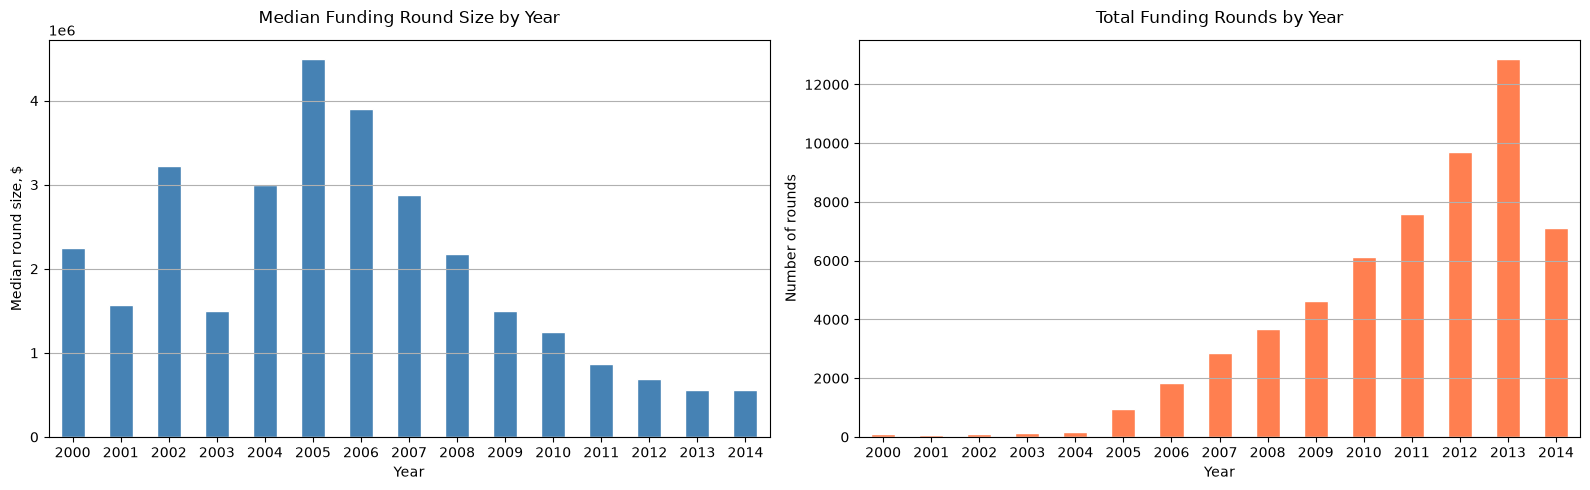

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Chart 1: median round size trends
median_round_by_year.plot(
    kind='bar',
    ax=axes[0],
    color='steelblue',
    edgecolor='white',
    rot=0
)

axes[0].set_title('Median Funding Round Size by Year',
                  fontsize=12, pad=12)
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Median round size, $')
axes[0].grid(axis='y')

# Chart 2: total round count trends
total_rounds_by_year.plot(
    kind='bar',
    ax=axes[1],
    color='coral',
    edgecolor='white',
    rot=0
)

axes[1].set_title('Total Funding Rounds by Year',
                  fontsize=12, pad=12)
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Number of rounds')
axes[1].grid(axis='y')

plt.tight_layout()
plt.show()

The charts show two opposing trends:

**Median round size** peaked in **2005** (4.5M) and has steadily declined since then, reaching just $560K by 2014. This may be explained by an increasing number of small startups entering the market and raising smaller amounts at early stages.

**The number of rounds**, by contrast, grew throughout the period — from 113 in 2000 to 12,880 in 2013. The decline in 2014 is explained by incomplete data.

**In 2014**, two trends were observed: round counts remained high (7,122), while the median amount per round (560K) was almost unchanged from 2013 (559K) — market activity continues to grow, but individual investment sizes have stabilized at a low level.

### Total Funding Trends in Mainstream Market Segments Growing in 2014

Create a pivot table of total funding by year and segment (excluding niche and mid):

In [59]:
pivot_funding = (investments_df[~investments_df['market'].isin(['niche', 'mid'])]
                 .pivot_table(
                     values='funding_total_usd',
                     index='mid_year',
                     columns='market',
                     aggfunc='sum'
                 ))

pivot_funding.tail()

market,Advertising,Analytics,Apps,Automotive,Big Data,Biotechnology,Clean Technology,Cloud Computing,Consulting,Curated Web,...,Social Media,Social Network Media,Software,Sports,Startups,Technology,Travel,Video,Web Hosting,unknown
mid_year,,,,,,,,,,,,,,,,,,,,,
2010,631617869,253739903,6123779,17696916,39233297,4894500078,1604429454,8525538,81264877,347018615,...,69447197,24043416,1520172121,38184989,2111966,312526805,44461808,79974203,534480485,159085659
2011,410730737,443333373,18374071,76452163,60369158,4967551850,1545603337,73151398,43413397,301918274,...,146004316,15271492,1533294661,16284258,19654403,143222700,77599608,26332122,307939045,150279236
2012,521137032,539214309,32601125,35557677,86413341,4931138800,958011189,74421582,65922756,356477186,...,208022824,22240195,1797265902,40993868,12358782,193334875,76296282,54968470,188581210,187250239
2013,524915135,622821367,28868621,117572526,78698922,5694269809,1203060535,84846778,93321324,466495409,...,179798339,25917742,1949165558,36208524,18080552,120873887,162123852,68222106,466925821,259004551
2014,207792333,151461613,66237730,69034162,79232600,2509638562,688686785,73440856,54298022,241754277,...,78894907,25075307,1352585721,33456511,41501837,202018937,78920274,54437714,56652385,609069074


Select segments that grew in 2014 compared with 2013:

In [60]:
growing_segments = pivot_funding.columns[
    pivot_funding.loc[2014] > pivot_funding.loc[2013]
]

print('Segments Growing in 2014:')
display(growing_segments.tolist())

Segments Growing in 2014:


['Apps',
 'Big Data',
 'Design',
 'Internet',
 'Manufacturing',
 'Medical',
 'Real Estate',
 'SaaS',
 'Startups',
 'Technology',
 'unknown']

Create a line chart for each growing segment, excluding unknown first:

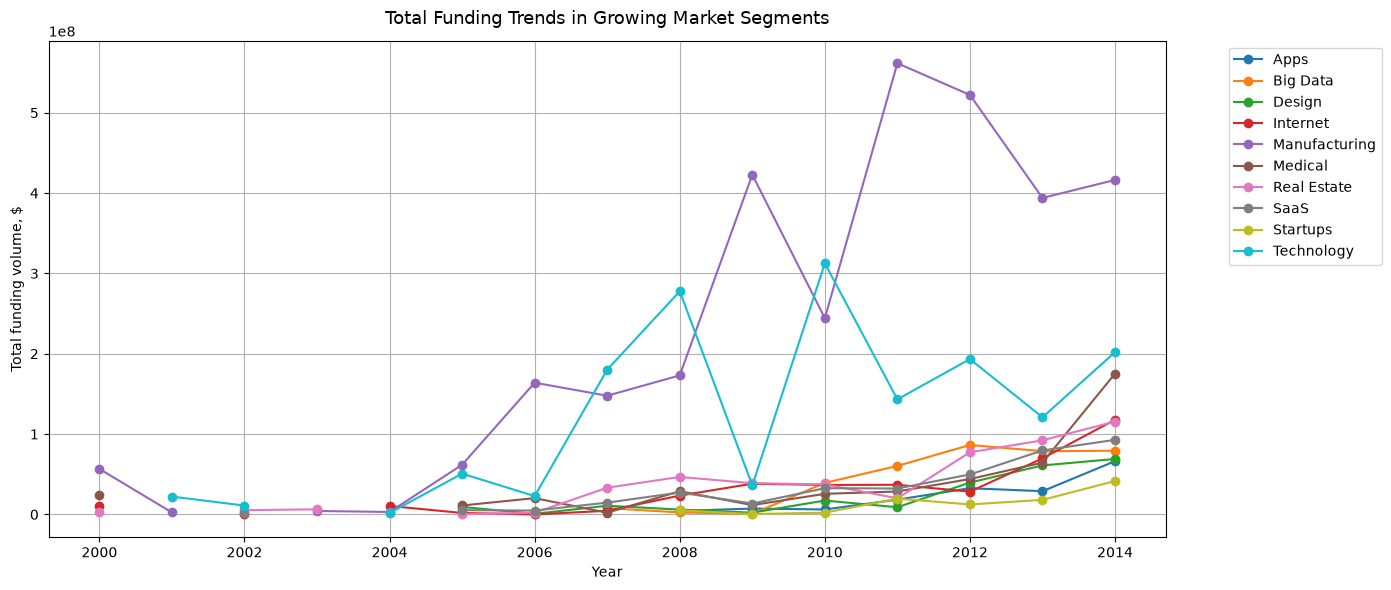

In [61]:
growing_segments_clean = [s for s in growing_segments if s != 'unknown']

fig, ax = plt.subplots(figsize=(14, 6))

for segment in growing_segments_clean:
    pivot_funding[segment].plot(
        kind='line',
        ax=ax,
        marker='o',
        linewidth=1.5,
        label=segment
    )

ax.set_title('Total Funding Trends in Growing Market Segments',
             fontsize=13, pad=12)
ax.set_xlabel('Year')
ax.set_ylabel('Total funding volume, $')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid()

plt.tight_layout()
plt.show()

Several groups can be identified among the segments growing in 2014:

**Fastest and strongest growth:**
- **Apps** — shows a sharp jump in 2014, becoming the total funding leader among growing segments (~600M). This reflects the mobile app boom.
- **Real Estate** and **Medical** — show steady growth in recent years, reaching ~$200M in 2014.
- **Technology** — despite volatility, shows strong growth by 2014.

**Moderate growth:**
- **Big Data**, **SaaS**, **Internet** — small but steadily growing segments, suggesting promising prospects.

**Manufacturing** stands out for high figures in 2011–2012, followed by a sharp decline, indicating segment instability.

Overall, **Apps**, **Medical**, and **Real Estate** appear most promising for investment — they show steady growth without sharp downturns.

### Annual Trends in the Share of Funds Returned by Funding Type

Prepare the data:

In [62]:
# Calculate total funding by year and type
funding_by_year = (investments_df.groupby('mid_year')[funding_types]
                   .sum())

display(funding_by_year.head())

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
mid_year,,,,,,,,,,,,,
2000,16759140.0,327962152.0,0.0,112202640.0,0.0,14000000.0,24086333.0,293114.0,0.0,3467747.0,0.0,7718867.0,0.0
2001,2667675.0,217519117.0,0.0,36596784.0,1500000.0,5829217.0,1000000.0,100000.0,0.0,0.0,0.0,0.0,0.0
2002,10465192.0,306940622.0,0.0,42323731.0,0.0,15309671.0,3000000.0,0.0,7500000.0,300000.0,0.0,0.0,0.0
2003,15318355.0,372234425.0,0.0,10280000.0,0.0,1050000.0,5629661.0,16850717.0,0.0,0.0,0.0,0.0,0.0
2004,18104728.0,664150451.0,0.0,62912359.0,0.0,30816623.0,11013741.0,10363600.0,0.0,0.0,0.0,0.0,0.0


Normalize returns by dividing return amounts by funding amounts for each year:
   - convert returns_df to dollars (multiply by 1e6)
   - add 1e-60 to the denominator to avoid division by zero.

Also replace anomalous values with NaN — values above 1 mean that returns exceed investments, which is an anomaly

In [63]:
normalized_returns = (returns_df[funding_types] * 1e6) / (funding_by_year[funding_types] + 1e-60)

normalized_returns = normalized_returns.where(normalized_returns <= 1)

display(normalized_returns.head())

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,0.996471,0.168922,0.0,0.697042,0.000000,0.618571,0.266956,0.0,0.000000,0.271069,0.0,0.025911,0.0
2001,NaN,0.107991,0.0,0.587483,0.006667,0.770258,NaN,0.0,0.000000,NaN,0.0,NaN,0.0
2002,0.629707,0.682282,0.0,0.608878,NaN,0.223388,NaN,0.0,0.201333,NaN,0.0,NaN,0.0
2003,0.505276,0.628260,0.0,0.914397,NaN,NaN,0.605720,0.0,NaN,NaN,0.0,NaN,0.0
2004,0.548476,0.837009,0.0,0.527559,NaN,0.439698,0.833504,0.0,NaN,NaN,0.0,NaN,0.0


Plot five funding types:

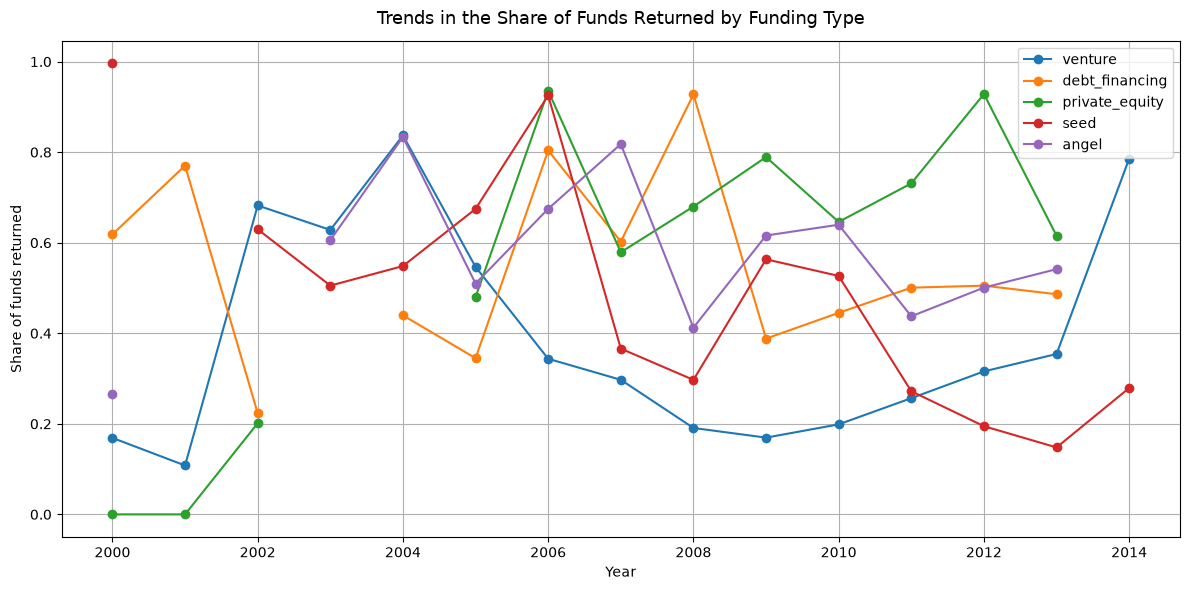

In [64]:
fig, ax = plt.subplots(figsize=(12, 6))

for col in ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']:
    normalized_returns[col].plot(
        kind='line',
        ax=ax,
        marker='o',
        linewidth=1.5,
        label=col
    )

ax.set_title('Trends in the Share of Funds Returned by Funding Type',
             fontsize=13, pad=12)
ax.set_xlabel('Year')
ax.set_ylabel('Share of funds returned')
ax.legend()
ax.grid()

plt.tight_layout()
plt.show()

The chart shows trends in the share of funds returned for five funding types.

**The most consistent growth** is observed for **venture** — after low values in 2008–2010 (0.17–0.20), the indicator grows steadily, reaching 0.79 in 2014. This suggests that venture financing is becoming increasingly effective in terms of returns.

**Private_equity** shows high values throughout the period (0.6–0.95), but with pronounced volatility — sharp rises and falls make this type less predictable.

**Debt_financing** and **angel** show moderate and relatively stable values in the 0.4–0.6 range, without a clear upward or downward trend.

**Seed** has the greatest volatility — from near-zero to maximum values (1.0 in 2000), suggesting high risk for this funding type.

**Conclusion:** **venture** shows the most consistent growth in the share of funds returned — this funding type has the best trend by 2014.

## Final Conclusions and Recommendations

### Overview of the Work Completed

The study loaded, preprocessed, and analyzed startup funding data from two datasets: `cb_investments` (54,294 companies) and `cb_returns` (15 years of return data). After preprocessing, outlier removal, and year filtering, the final sample contained **35,587 companies** for 2000–2014.

---

### Key Findings

**Market structure:**
- Most companies receive one-off funding, but most capital is concentrated in companies with long investment cycles (over a year).
- The market is highly fragmented — 73% of segments are niche.

**Funding types:**
- **Venture** — the clear leader in volume (128.6B), popularity (18,761 companies), and returns (40.6B).
- **Seed** — the second most popular type, but with highly volatile returns.
- **Debt_financing** and **private_equity** — infrequent but large deals with strong return figures.

**Market trends:**
- Funding round counts grew steadily from 2000 to 2013.
- The median amount per round declined from 2005 — the market is becoming more accessible, but amounts are smaller.
- By 2014, **Apps**, **Medical**, and **Real Estate** are the fastest-growing segments.

**Returns:**
- Venture financing shows consistent growth in the share of funds returned by 2014 — the most promising trend among all types.

---

### Recommendations (as of 2015)

**Which industry to invest in:**
We recommend focusing on three segments:

- **Apps** — shows sharp funding growth in 2014, reflecting the mobile app boom. High growth potential.
- **Medical** — steady growth over several years and stable demand regardless of economic cycles.
- **SaaS** — a small but steadily growing segment with highly scalable business models.

**Which funding type to choose:**
We recommend **venture financing**, which leads across all key indicators:
- the largest total amount of funds raised;
- the greatest popularity among companies;
- consistent growth in the share of funds returned by 2014.

As a complement, consider **debt_financing** — it is rarely used, but features large deals and stable returns (~$4.7B), making it attractive for a conservative strategy.

**Summary:** the optimal strategy for 2015 is venture investment in **Apps** and **Medical** companies, which show steady growth and high return potential.